In [1]:
# Importing dependencies
import cv2
import os
import random
import numpy as np
from matplotlib import pyplot as plt
import uuid

# Importing tensorflow dependencies
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Layer, Conv2D, Dense, MaxPooling2D, Input, Flatten
import tensorflow as tf

In [4]:
# Setup paths
pos_path = "data/positive"
neg_path = "data/negative"
anc_path = "data/anchor"

os.makedirs(pos_path, exist_ok=True)
os.makedirs(neg_path, exist_ok=True)
os.makedirs(anc_path, exist_ok=True)

# Delete all files in the path
# for file in os.listdir(pos_path):
#     file_path = os.path.join(pos_path, file)

#     if os.path.isfile(file_path):
#         os.remove(file_path)

print(f"Total Anchor images: {len(os.listdir(anc_path))}")
print(f"Total Positive images: {len(os.listdir(pos_path))}")

Total Anchor images: 167
Total Positive images: 146


In [5]:
cap=cv2.VideoCapture(0)
cap.set(cv2.CAP_PROP_FRAME_WIDTH, 250)
cap.set(cv2.CAP_PROP_FRAME_HEIGHT, 250)

while cap.isOpened():
    success, frame=cap.read()

    cv2.imshow("Image", frame)

    if cv2.waitKey(1)& 0xFF==ord("a"):
        name=os.path.join(anc_path, "{}.jpg".format(uuid.uuid1()))
        cv2.imwrite(name,frame)

    if cv2.waitKey(1)& 0xFF==ord("p"):
            name=os.path.join(pos_path, "{}.jpg".format(uuid.uuid1()))
            cv2.imwrite(name,frame)

    if cv2.waitKey(1) & 0xFF == ord("q"):
        break
    if cv2.getWindowProperty("Image", cv2.WND_PROP_VISIBLE) < 1:
        break

cap.release()
cv2.destroyAllWindows()

Get Image Directories

In [6]:
anchor=tf.data.Dataset.list_files(anc_path+"/*.jpg").take(300)
positive=tf.data.Dataset.list_files(pos_path+"/*.jpg").take(300)
negative=tf.data.Dataset.list_files(neg_path+"/*.jpg").take(300)

In [7]:
dir=anchor.as_numpy_iterator()
dir.next()

b'data\\anchor\\4e1a2e5f-a30f-11f1-9bf9-580205016a5a.jpg'

Preprocessing

In [ ]:
def preprocess(file_path):
    # Read file from disk as raw bytes
    byte_img=tf.io.read_file(file_path)

    # Decode JPEG into uint8 tensor (H, W, 3)
    # converts the .jpg photo file into a 3D grid of color numbers (Red, Green, Blue)
    img=tf.io.decode_jpeg(byte_img)

    # Resize to standard target dimensions (105x105)
    img =tf.image.resize(img,(105,105))

    # Rescale pixel values from [0, 255] to [0.0, 1.0]
    img=img/255.0
    
    return img

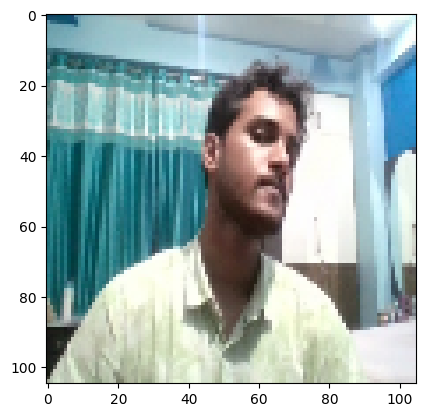

In [9]:
plt.imshow(preprocess(dir.next()))

Create labelled Data

In [10]:
# Get total count of anchor samples
num_samples = len(anchor)


# --- Step 1: Create Label Streams ---
# Stream of 1.0s for positive pairs
pos_labels = tf.data.Dataset.from_tensor_slices(tf.ones(num_samples))

# Stream of 0.0s for negative pairs
neg_labels = tf.data.Dataset.from_tensor_slices(tf.zeros(num_samples))


# --- Step 2: Build Positive & Negative Dataset Tuples ---
# Form tuples: (anchor_img, positive_img, 1.0)
positives = tf.data.Dataset.zip((anchor, positive, pos_labels))

# Form tuples: (anchor_img, negative_img, 0.0)
negatives = tf.data.Dataset.zip((anchor, negative, neg_labels))


# --- Step 3: Combine Datasets ---
# Merge both datasets sequentially into one master dataset
data = positives.concatenate(negatives)

In [11]:
samples=data.as_numpy_iterator()
sample=samples.next()

In [12]:
print(f"Total rows: {len(data)}")
print(f"Total Columns: {len(sample)}")

Total rows: 313
Total Columns: 3


Test and Train Partition

In [13]:
def preprocess_Twin(inpImg, valImg, label):
    return (preprocess(inpImg), preprocess(valImg), label)

In [14]:
# These two lines are identical : preprocess_Twin(*sample)
preprocess_Twin(sample[0], sample[1], sample[2])

(<tf.Tensor: shape=(105, 105, 3), dtype=float32, numpy=
 array([[[0.02038762, 0.22163372, 0.3284826 ],
         [0.0104898 , 0.19775909, 0.31540617],
         [0.03095238, 0.22037615, 0.34677738],
         ...,
         [0.86745495, 0.9874136 , 0.98745894],
         [0.79787105, 0.9306017 , 0.98296916],
         [0.73476195, 0.8637583 , 0.9390989 ]],
 
        [[0.05485262, 0.24497746, 0.34802642],
         [0.03738215, 0.24955422, 0.35398   ],
         [0.0363372 , 0.26331466, 0.37039217],
         ...,
         [0.8093677 , 0.9172296 , 0.94201016],
         [0.75690836, 0.88239855, 0.9348051 ],
         [0.7578899 , 0.89367974, 0.94527644]],
 
        [[0.297519  , 0.4912885 , 0.57291716],
         [0.20917167, 0.43099642, 0.50641453],
         [0.14995332, 0.38686812, 0.46391892],
         ...,
         [0.7148393 , 0.8380886 , 0.8826264 ],
         [0.7354503 , 0.8616009 , 0.9034175 ],
         [0.82684976, 0.9534604 , 0.97164893]],
 
        ...,
 
        [[0.05754832, 0.07853805

In [15]:
# Applies preprocessing to all image pairsdat
data=data.map(preprocess_Twin)

# Speeds up model training across epochs
data=data.cache()

# Randomy shuffles dataset samples
data=data.shuffle(buffer_size=1024)

In [16]:
# Traning partition

# Takes 80% samples for trainging
train_data=data.take(round(len(data)* 0.8))

# Combine individual samples in mini-batches of 16 pairs
train_data=train_data.batch(16)

# Pre-fetches the next 8 batches into memory while current batch is in use.
# This prevents data bottlenecks during GPU model training.
train_data=train_data.prefetch(8)

train_data
 ├── Batch 1  ---> (X_anchor, X_validation, Y_label)   # 16 pairs
 ├── Batch 2  ---> (X_anchor, X_validation, Y_label)   # 16 pairs
 ├── Batch 3  ---> (X_anchor, X_validation, Y_label)   # 16 pairs
 └── ...


In [17]:
# Testing partition

# Skips first 80% samples as they are training data
test_data=data.skip(round(len(data)*0.8))
test_data=test_data.take(round(len(data)*0.2))

test_data=train_data.batch(16)
test_data=train_data.prefetch(8)

MODEL ENGINEERING

What is the Keras Functional API?
In Keras/TensorFlow, there are two ways to build neural network architectures

1. Sequential API : A simple straight line where data flows from Layer A -> Layer B -> Layer C. It can only handle 1 input and 1 output.

2. Functional API : A flexible way to build complex models. Layers act like functions that take inputs and return outputs: x = Dense(64)(input_tensor).

In [18]:
# Defines the input entry point of your Neural Network (using the Keras Functional API).
# It tells the network what shape of image data to expect.
inp =Input(shape=(105,105,3), name ="input_img")

# 64 filters of size 10x10 pixels with ReLu AF
c1= Conv2D(64, (10,10), activation='relu')(inp)

# It slides a small window across each feature map and keeps only the maximum pixel 
# value in that window.
m1=MaxPooling2D((2,2), padding="same")(c1)

In [19]:
print(inp)
print(c1)
print(m1)

<KerasTensor shape=(None, 105, 105, 3), dtype=float32, sparse=False, ragged=False, name=input_img>
<KerasTensor shape=(None, 96, 96, 64), dtype=float32, sparse=False, ragged=False, name=keras_tensor>
<KerasTensor shape=(None, 48, 48, 64), dtype=float32, sparse=False, ragged=False, name=keras_tensor_1>


In [20]:
def make_embedding():
    inp =Input(shape=(105,105,3), name ="input_img")

    # First block
    c1= Conv2D(64, (10,10), activation='relu')(inp)
    m1=MaxPooling2D((2,2), padding="same")(c1)
    
    # Second block
    c2= Conv2D(128, (7,7), activation='relu')(m1)
    m2=MaxPooling2D((2,2), padding="same")(c2)

    # Third block
    c3= Conv2D(128, (4,4), activation='relu')(m2)
    m3=MaxPooling2D((2,2), padding="same")(c3)

    # Final embedding block
    c4= Conv2D(256, (4,4), activation='relu')(m3)
    f1=Flatten()(c4)
    d1=Dense(4096, activation="sigmoid")(f1) 
    
    # Return the Keras Model object
    return Model(inputs=[inp], outputs=[d1], name="embedding")

In [21]:
embedding=make_embedding()
embedding.summary()

Model: "embedding"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_img (InputLayer)          │ (None, 105, 105, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 96, 96, 64)     │        19,264 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 48, 48, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 42, 42, 128)    │       401,536 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 21, 21, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 18, 18, 128)    │       262,272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 9, 9, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 6, 6, 256)      │       524,544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 9216)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 4096)           │    37,752,832 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 38,960,448 (148.62 MB)

 Trainable params: 38,960,448 (148.62 MB)

 Non-trainable params: 0 (0.00 B)

Conv2D Paramters = (Filter Height × Filter Width × Input Channels + 1) × No. of Filters

Dense Paramters = (Input Units + 1) × Output Units

In [22]:
# Calculates the difference between two face embeddings in a Siamese Neural Network.

# (Layer) indicates inheritance
# Inherited from tf.keras.layers.Layer to build a custom Keras layer
class L1Dist(Layer):

    # Constructor method
    def __init__(self, **kwargs):

        # Super refers parent class and init calls parent class constructor
        super().__init__(**kwargs)



    # "call" defines the actual computation logic that executes when data flows 
    # through this layer during model inference or training
    # Takes 'inputs' as a single list: [input_embedding, validation_embedding]
    def call(self, inputs):
        # Unpack the list into two separate variables
        input_embedding, validation_embedding = inputs
        
        # Step 2: Unwrap inner lists if Keras 3 wrapped them in [[Tensor1], [Tensor2]]
        if isinstance(input_embedding, (list, tuple)):
            input_embedding = input_embedding[0]
        if isinstance(validation_embedding, (list, tuple)):
            validation_embedding = validation_embedding[0]

        # Returns the resulting 4,096-dimensional distance vector |E_1 - E_2| to be 
        # passed into the final classification layer
        return tf.math.abs(input_embedding-validation_embedding)

In [23]:
#  Function that builds and returns the full Siamese Neural Network.
def make_siamese_model():

    # Anchor and validation image inputs
    input_image = Input(name='input_img', shape=(105, 105, 3))
    validation_image = Input(name='validation_img', shape=(105, 105, 3))

    # Combine siamese distance components (pass inputs as a list [...])
    siamese_layer = L1Dist()
    siamese_layer._name = 'distance'
    distances = siamese_layer([embedding(input_image), embedding(validation_image)])

    # Classification layer
    classifier = Dense(1, activation='sigmoid')(distances)

    return Model(inputs=[input_image, validation_image], outputs=classifier, name='SiameseNetwork')


In [24]:
siamese_model=make_siamese_model()
siamese_model.summary()

Model: "SiameseNetwork"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_img           │ (None, 105, 105,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ validation_img      │ (None, 105, 105,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding           │ (None, 4096)      │ 38,960,448 │ input_img[0][0],  │
│ (Functional)        │                   │            │ validation_img[0… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ l1_dist (L1Dist)    │ (None, 4096)      │          0 │ embedding[0][0],  │
│                     │                   │            │ embedding[1][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 1)         │      4,097 │ l1_dist[0][0]     │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 38,964,545 (148.64 MB)

 Trainable params: 38,964,545 (148.64 MB)

 Non-trainable params: 0 (0.00 B)

TRAINING

In [25]:
# Setup loss and optimizer
binary_cross_loss=tf.losses.BinaryCrossentropy()
optimizer=tf.keras.optimizers.Adam(1e-4) #  learning rate = 0.0001


# Establishing Checkpoints.

# folder path where model checkpoints will be stored
checkpoint_dir='./training_checkpoints'
os.makedirs(checkpoint_dir, exist_ok=True)
checkpoint_prefix=os.path.join(checkpoint_dir,'ckpt')           # "opt" stores the Adam optimizer momentum
checkpoint=tf.train.Checkpoint(opt=optimizer, sm=siamese_model) # 'sm' -> stores the Siamese Network weights.

In [26]:
# Build train-step function which focues on training one batch

# @tf.function is a Python decorator that compiles your Python code into a high-performance C++ TensorFlow computation graph
# Python execution is easy to debug, but slow, @tf.function speeds up your training loop by 2x to 5x!
@tf.function
def train_step(batch):
    
    # It "records" every math operation executed during the forward pass inside with block
    # and compute exact derivatives (gradients) during backpropagation.
    with tf.GradientTape() as tape:

        # Get anchor and +ve/-ve img
        x=[batch[0], batch[1]]

        # Get label
        y=batch[2]

        # Forward pass: Feed twin images into Siamese Network
        # (training=True ensures layers like Dropout/BatchNorm behave correctly during training)
        yPred=siamese_model(x, training=True)

        # Calculate loss
        loss=binary_cross_loss(y, yPred)
    
    # Compute gradients of the loss with respect to all trainable weights
    # siamese_model.trainable_variables is a list containing every single trainable weight matrix and bias vector across all layers
    # gradients is a list of derivative tensors matching the exact shapes of trainable_variables
    gradient=tape.gradient(loss, siamese_model.trainable_variables)

    # Update model weights using the Adam optimizer
    # zip(gradients, trainable_variables) pairs each gradient with its corresponding weight tensor
    # For every paired weight $w$ and gradient $g$, the Adam optimizer updates the weight in memory
    optimizer.apply_gradients(zip(gradient,siamese_model.trainable_variables))

    return loss

In [27]:
def train(train_data, epochs):
    
     # Loop through epochs
     for epoch in range(1, epochs+1):
        print(f"Epoch {epoch}/{epochs}")
        progressBar=tf.keras.utils.Progbar(len(train_data))

        # Inner loop iterating through every mini-batch of 16 image pairs.
        for idx, batch in enumerate(train_data): # idx is batch index, batch is Tuple containing (X_anchor, X_val, y_true)
            
            # Calls your @tf.function compiled training step to compute loss, backpropagate gradients and update model weights for this batch.
            # Also capture batch loss
            loss = train_step(batch)
            progressBar.update(idx+1)
        
        # Save checkpoints after every epoch
        # checkpoint.save(file_prefix=checkpoint_prefix)
    
    # Save model
     siamese_model.save_weights(os.path.join(checkpoint_dir, 'siamese_weights.weights.h5'))

In [28]:
# Train the model

epochs=10

train(train_data, epochs)

Epoch 1/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 21s 1s/step
Epoch 2/10
 2/16 ━━━━━━━━━━━━━━━━━━━━ 14s 1s/step   

KeyboardInterrupt: 

In [ ]:
# Loading weights

# Create a fresh model instance with empty architecture
# siamese_model = make_siamese_model()

# Load your trained weights from the .h5 file
# weights_path = os.path.join('./training_checkpoints', 'siamese_weights.weights.h5')
# siamese_model.load_weights(weights_path)

# print("Trained weights loaded successfully!")

Model Evaluation

In [29]:
# Import metrics    
from tensorflow.keras.metrics import Recall, Precision

# Doing predictions
test_input, test_val, y_true=test_data.as_numpy_iterator().next()
y_pred=siamese_model.predict([test_input, test_val])


1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 587ms/step


In [30]:
# Post processing results

result=[]

for pred in y_pred:
    if pred>0.5:
        result.append(1)
    else :
        result.append(0)

result

[0, 0, 0, 1, 1, 0, 0, 0, 1, 1, 0, 0, 1, 1, 0, 1]

In [31]:
# Calculate metrics

r=Recall()
p=Precision()

r.update_state(y_true, y_pred)
p.update_state(y_true, y_pred)

print('Recall: ',r.result().numpy())
print('Precision: ',p.result().numpy())

Recall:  1.0
Precision:  1.0


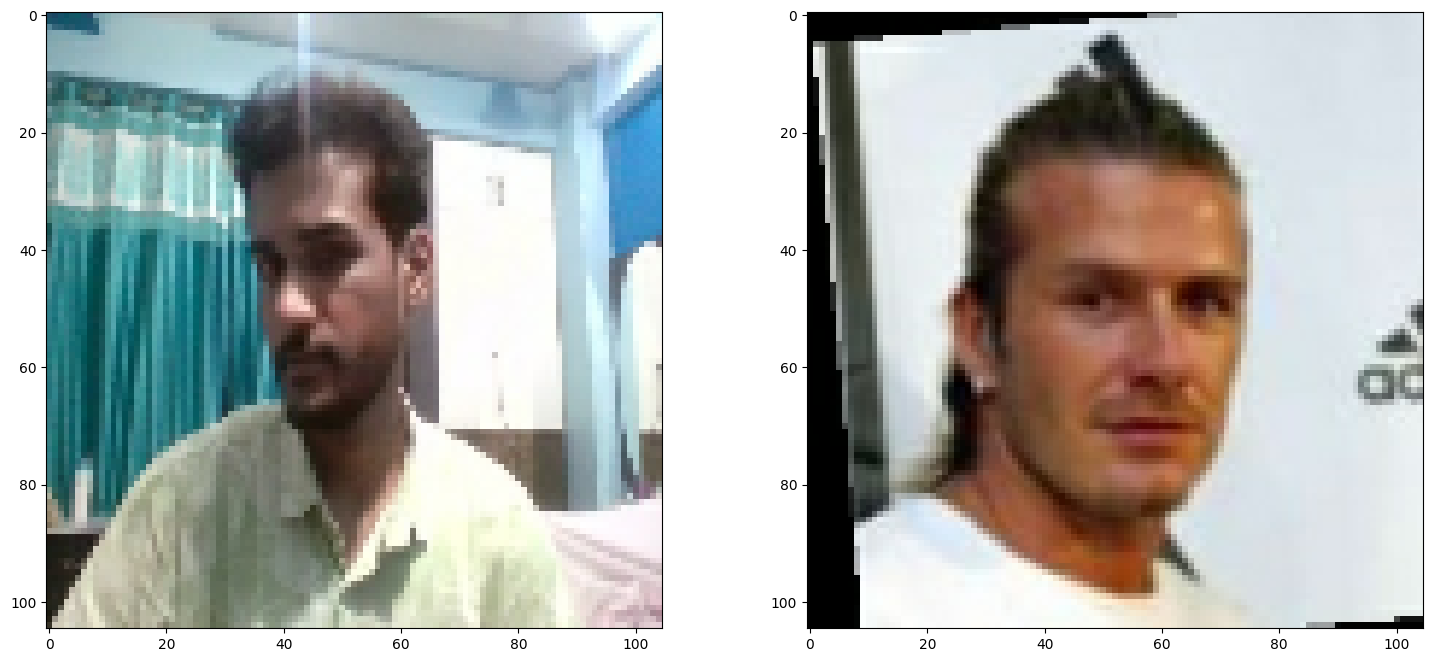

In [32]:
# Visaulizing results

# Set the plot size
plt.figure(figsize=(18,8))

# Make a grid of row=1, col=2 and give the plot index=1
plt.subplot(1,2,1)
plt.imshow(test_input[0])

# Make a grid of row=1, col=2 and give the plot index=2
plt.subplot(1,2,2)
plt.imshow(test_val[0])

plt.show()

In [ ]:
# Save model
siamese_model.save('model.h5')

In [33]:
# Reload model
model=tf.keras.models.load_model('model.h5',
custom_objects={'L1Dist':L1Dist, 'binary_cross_loss':tf.losses.binary_crossentropy})

In [34]:
# Make predictions with loaded model 
model.predict([test_input, test_val])

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 533ms/step


array([[6.5855791e-05],
       [3.1439475e-07],
       [5.5366504e-06],
       [9.9999303e-01],
       [9.9999928e-01],
       [1.8095490e-06],
       [6.8295898e-04],
       [1.9935949e-07],
       [9.9980956e-01],
       [9.9734282e-01],
       [8.9670371e-05],
       [1.4772494e-03],
       [9.9999994e-01],
       [9.9999636e-01],
       [6.8880119e-08],
       [9.9984682e-01]], dtype=float32)

Real time test

In [35]:
# Verification function 

def verify(model, detection_threshold, verification_threshold):

    results=[]
    verification_folder=os.listdir(os.path.join('application_data','verification_images'))

    for image in verification_folder:

        input_image=preprocess(os.path.join('application_data','input_image','input_image.jpg'))
        validation_image=preprocess(os.path.join('application_data','verification_images', image))

        # np.expand_dims inserts an extra dimension of size 1 at the specified axis
        # Add batch dimension to create 4D tensors: (1, 100, 100, 3)
        input_batch = np.expand_dims(input_image, axis=0)
        val_batch = np.expand_dims(validation_image, axis=0)

        # make predictions 
        result = model.predict([input_batch, val_batch], verbose=0)
        results.append(result)
    
    # np.sum() counts the total number of True matches {eg. 3 out of 5 photos}
    detection=np.sum(np.array(results) > detection_threshold)
    verification=detection/len(verification_folder)
    verified=verification>verification_threshold

    return results, verified


In [ ]:
cap= cv2.VideoCapture(0)
cap.set(cv2.CAP_PROP_FRAME_HEIGHT,250)
cap.set(cv2.CAP_PROP_FRAME_WIDTH,250)

while cap.isOpened():
    success, frame =cap.read()
    
    cv2.imshow('Verification', frame)

    # capture photo 
    if cv2.waitKey(1) & 0xFF == ord('c'):

        # save image in applicaton_data/input_image folder 
        folder=os.path.join('application_data','input_image', 'input_image.jpg')
        cv2.imwrite(folder, frame)

        # do verification 
        results, verified = verify(model, 0.5, 0.5)
        print(verified)


    if cv2.waitKey(1) & 0xFF == ord('q'):
        break
    if cv2.getWindowProperty("Verification", cv2.WND_PROP_VISIBLE) < 1:
        break

cap.release()
cv2.destroyAllWindows()

In [ ]:
np.sum(np.squeeze(results) > 0.5)